# 01 · Exploratory data analysis: Strathcona heavy-oil wells

A first look at the three competition files, so the team gets a feel for what is in them before picking a research question.

| File | Grain | What it holds |
|---|---|---|
| `daily_production` | well × day | volumes, downtime, pressures, pump sensors |
| `well_jobs` | one row per job | maintenance / workover / drilling jobs, cost estimates |
| `production_failures` | one row per failure | what broke, why, and when |

**Sections:** 1 Setup · 2 Data quality · 3 The well fleet · 4 Production · 5 Downtime and lost oil · 6 Pump sensors · 7 Failures · 8 Jobs and cost · 9 Linking the files · 10 Takeaways

## 1 · Setup

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Find the data folder whether the notebook runs from the repo root or from notebooks/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "Competition Dataset").exists())
DATA = ROOT / "data" / "Competition Dataset"

# ---- Chart palette (colorblind-validated categorical order; never cycle past 8) ----
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA, YELLOW = SERIES[:4]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ_BLUES = LinearSegmentedColormap.from_list(
    "seq_blues", ["#f4f8fe", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (11, 4),
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.prop_cycle": plt.cycler(color=SERIES),
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 9,
})

thousands = mtick.FuncFormatter(lambda x, _: f"{x:,.0f}")

def hbar(ax, s, fmt="{:,.0f}", color=BLUE, title=None, xlabel=None):
    """Horizontal ranked bar chart with value labels."""
    s = s.dropna().sort_values()
    bars = ax.barh([str(i) for i in s.index], s.values, color=color, height=0.68)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.xaxis.set_major_formatter(thousands)
    for b, v in zip(bars, s.values):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2, "  " + fmt.format(v),
                va="center", fontsize=8, color=INK2)
    ax.margins(x=0.15)
    ax.tick_params(axis="y", length=0, labelcolor=INK2)
    if title: ax.set_title(title)
    if xlabel: ax.set_xlabel(xlabel)
    return ax

def end_label(ax, x, y, text, color=INK2):
    """Direct label at the end of a line, in text ink (never the series color)."""
    ax.annotate(text, (x, y), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=color)

def load(name, columns=None, drop=()):
    """Read a parquet file: strings -> category, decimals/doubles -> float32, dates -> datetime64[ns]."""
    t = pq.read_table(DATA / f"{name}.parquet", columns=columns)
    t = t.select([c for c in t.column_names if c not in drop])
    fields = []
    for f in t.schema:
        if pa.types.is_decimal(f.type) or pa.types.is_floating(f.type):
            fields.append(pa.field(f.name, pa.float32()))
        else:
            fields.append(f)
    t = t.cast(pa.schema(fields))
    df = t.to_pandas(strings_to_categorical=True, date_as_object=False)
    for c in df.columns:
        if pd.api.types.is_datetime64_any_dtype(df[c]):
            df[c] = df[c].astype("datetime64[ns]")
    return df

In [2]:
%%time
# Skip a few long free-text / duplicate columns in the big file to keep memory down
dp = load("daily_production", drop=("pcp_pump_comment", "pcp_pump_name", "well_name", "formatted_uwi"))
jobs = load("well_jobs")
fails = load("production_failures")

for name, df in [("daily_production", dp), ("well_jobs", jobs), ("production_failures", fails)]:
    print(f"{name:20s} {len(df):>10,} rows  {df.shape[1]:>3} cols  {df.uwi.nunique():>5,} wells  "
          f"{df.memory_usage(deep=True).sum()/1e6:,.0f} MB")

daily_production      5,075,590 rows   37 cols  2,905 wells  619 MB
well_jobs                15,610 rows   19 cols  1,903 wells  9 MB
production_failures       2,873 rows   18 cols    825 wells  1 MB
CPU times: total: 9.53 s
Wall time: 1.44 s


In [3]:
dp.head(3).T

,0,1,2
uwi,100142303701W400,141092703528W300,111152503528W300
field_operating_area,Bodo East,Cactus Lake,Cactus Lake
province,AB,SK,SK
surface_latitude,52.196346,52.036777,52.03978
surface_longitude,-110.055336,-109.909225,-109.868073
on_production_date,2018-10-02 00:00:00,1980-07-19 00:00:00,2014-08-24 00:00:00
facility_name,NaN,Cactus EOR 12-21 Polymer Injection,Cactus Lake 16-27-035-28W3 BTY
well_daily_status,Producing,Injecting,Producing
primary_fluid_type,Heavy Oil,Polymer,Heavy Oil
flow_direction,production,injection,production


## 2 · Data quality

Before modelling anything: which columns are actually populated? Sensor columns only exist for wells with that equipment, and some columns are empty by design.

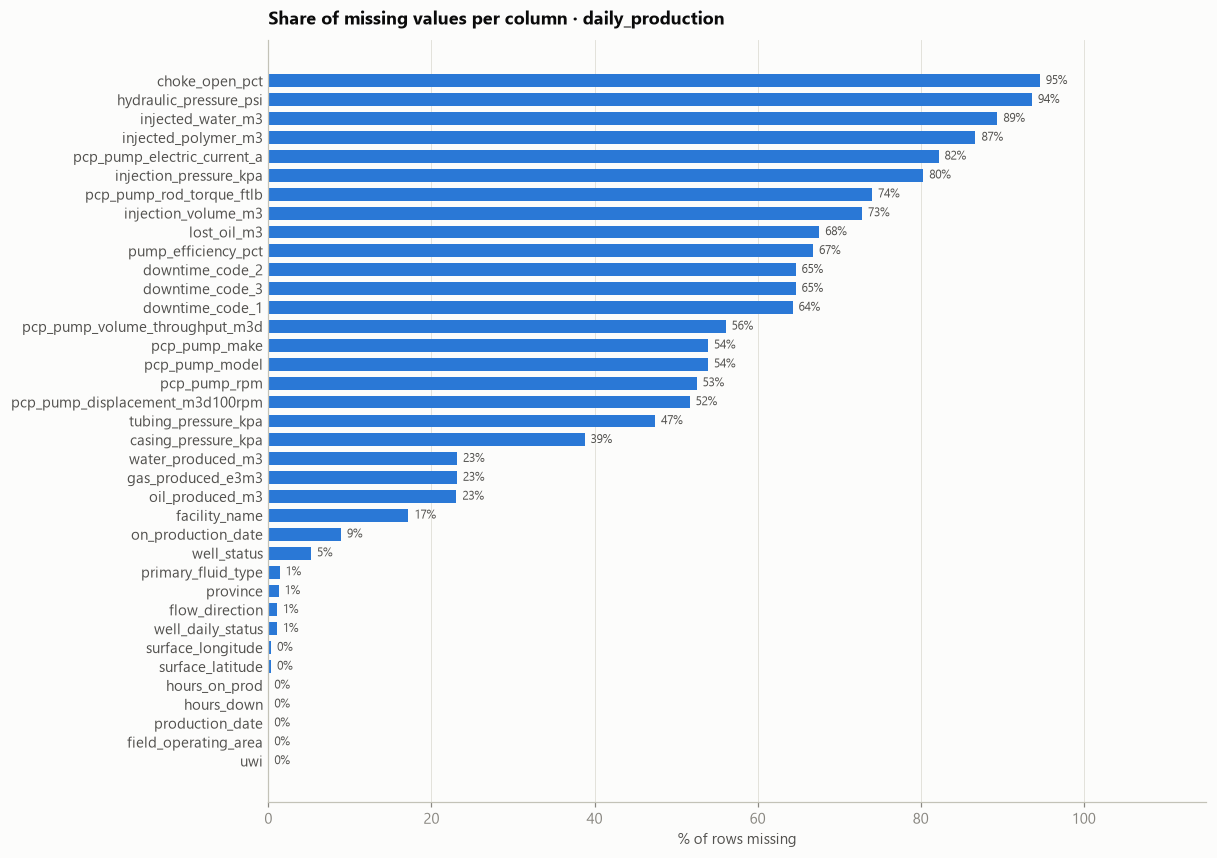

In [4]:
null_share = dp.isna().mean().sort_values()
fig, ax = plt.subplots(figsize=(11, 9))
hbar(ax, null_share * 100, fmt="{:.0f}%", title="Share of missing values per column · daily_production",
     xlabel="% of rows missing")
ax.set_xlim(0, 115)
plt.show()

In [5]:
# Placeholder / impossible values the handbook warns about
checks = {
    "tubing_pressure_kpa >= 99,999 (placeholder)": (dp.tubing_pressure_kpa >= 99_999).sum(),
    "casing_pressure_kpa >= 99,999": (dp.casing_pressure_kpa >= 99_999).sum(),
    "hours_down + hours_on_prod > 24.5": ((dp.hours_down.fillna(0) + dp.hours_on_prod.fillna(0)) > 24.5).sum(),
    "negative oil_produced_m3": (dp.oil_produced_m3 < 0).sum(),
    "pump_efficiency_pct > 2 (i.e. >200%)": (dp.pump_efficiency_pct > 2).sum(),
    "duplicate (uwi, production_date) rows": dp.duplicated(["uwi", "production_date"]).sum(),
    "jobs with negative duration": (jobs.job_duration_days < 0).sum(),
    "jobs with no field cost estimate": jobs.field_est_total.isna().sum(),
}
pd.Series(checks, name="rows").to_frame().style.format("{:,}")

,rows
"tubing_pressure_kpa >= 99,999 (placeholder)",10
"casing_pressure_kpa >= 99,999",0
hours_down + hours_on_prod > 24.5,0
negative oil_produced_m3,"3,720"
pump_efficiency_pct > 2 (i.e. >200%),"10,226"
"duplicate (uwi, production_date) rows",29
jobs with negative duration,65
jobs with no field cost estimate,0


**Are the "sensor" columns really live?** For each well, how often does a tag's value change from one day to the next? A live historian tag changes almost every day. A value that is typed in by hand and carried forward changes only when someone takes a new reading.

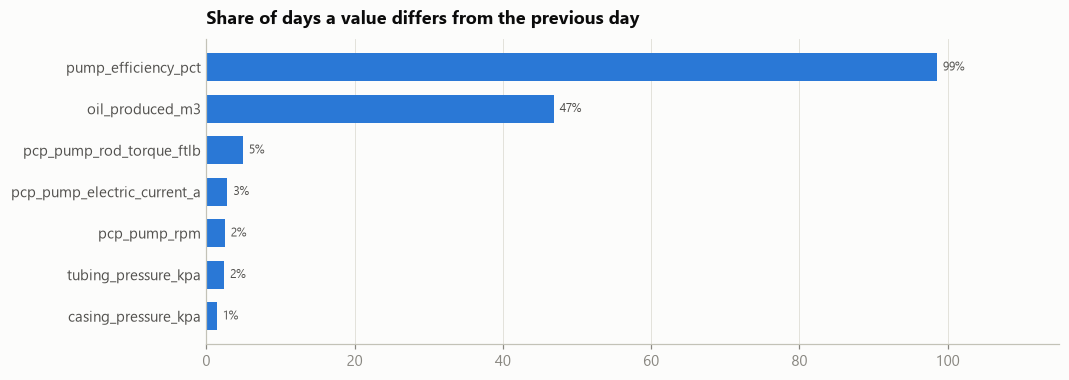

In [6]:
dps = dp.sort_values(["uwi", "production_date"])
tags = ["pump_efficiency_pct", "oil_produced_m3", "casing_pressure_kpa", "pcp_pump_rod_torque_ftlb",
        "pcp_pump_electric_current_a", "pcp_pump_rpm", "tubing_pressure_kpa"]
change = {}
for c in tags:
    s = dps[["uwi", c]].dropna()
    change[c] = (s.groupby("uwi", observed=True)[c].diff().fillna(0) != 0).mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
hbar(ax, pd.Series(change) * 100, fmt="{:.0f}%", title="Share of days a value differs from the previous day")
ax.set_xlim(0, 115)
plt.show()
del dps

> Torque, motor current, RPM and tubing pressure change on only a few percent of days. They behave like **periodic manual readings carried forward**, not continuous sensor streams. Pump efficiency (derived from daily volumes) changes every day, so it is the most useful daily health signal.

## 3 · The well fleet

About three quarters of the wells produce and about a quarter inject water/polymer to push oil toward the producers. Where are they, and how has the active count changed?

In [7]:
# One row per well: location, area, role, totals
last = dp.sort_values("production_date").groupby("uwi", observed=True).tail(1).set_index("uwi")
wells = dp.groupby("uwi", observed=True).agg(
    lat=("surface_latitude", "first"), lon=("surface_longitude", "first"),
    area=("field_operating_area", "first"), province=("province", "first"),
    oil_total=("oil_produced_m3", "sum"), water_total=("water_produced_m3", "sum"),
    inj_total=("injection_volume_m3", "sum"),
    days=("production_date", "size"),
)
wells["role"] = np.where(wells.inj_total > wells.oil_total + wells.water_total, "Injector", "Producer")
wells["last_status"] = last.well_daily_status.astype(str)
print(wells.role.value_counts().to_string(), "\n")
print(wells.province.value_counts().to_string())

role
Producer    2296
Injector     609 

province
SK    2382
AB     438
BC      49


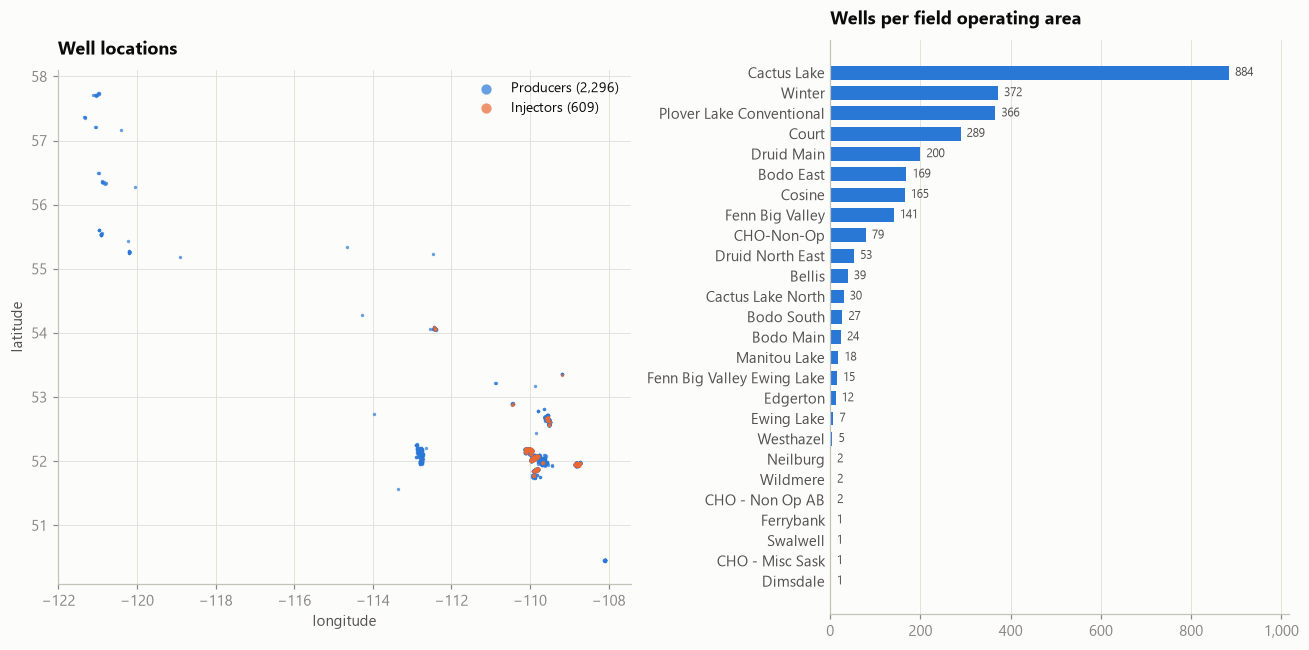

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), gridspec_kw={"width_ratios": [1.25, 1]})
for role, color in [("Producer", BLUE), ("Injector", ORANGE)]:
    w = wells[wells.role == role]
    ax1.scatter(w.lon, w.lat, s=5, color=color, alpha=0.7, linewidths=0, label=f"{role}s ({len(w):,})")
ax1.set_aspect(1 / np.cos(np.deg2rad(wells.lat.mean())))
ax1.grid(visible=True, axis="both")
ax1.set_title("Well locations")
ax1.set_xlabel("longitude"); ax1.set_ylabel("latitude")
ax1.legend(loc="upper right", markerscale=3)

hbar(ax2, wells.area.astype(str).value_counts(), title="Wells per field operating area")
plt.tight_layout(); plt.show()

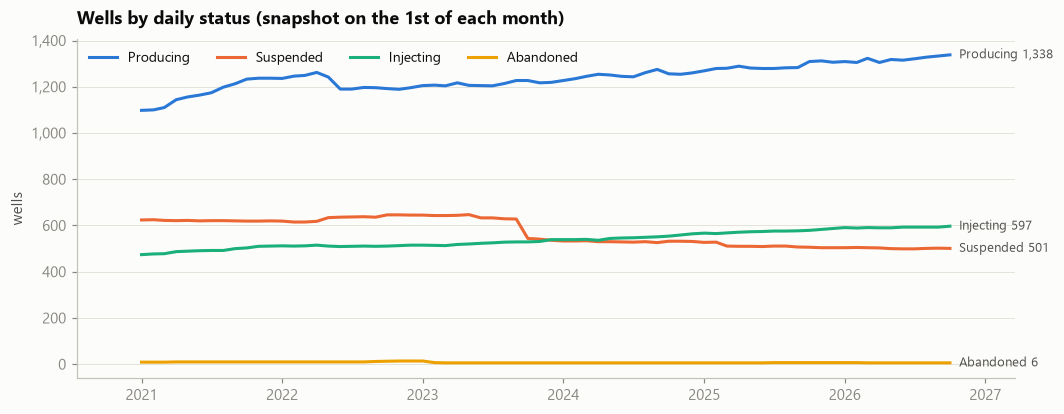

In [9]:
# How many wells sit in each status on the 1st of every month
monthly_status = (dp[dp.production_date.dt.day == 1]
                  .groupby(["production_date", "well_daily_status"], observed=True).size()
                  .unstack(fill_value=0))
top = monthly_status.sum().sort_values(ascending=False).index[:4]
status_colors = dict(zip(top, SERIES))

fig, ax = plt.subplots()
for s in top:
    y = monthly_status[s]
    ax.plot(y.index, y.values, color=status_colors[s], label=s)
    end_label(ax, y.index[-1], y.values[-1], f"{s} {y.values[-1]:,}")
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Wells by daily status (snapshot on the 1st of each month)")
ax.set_ylabel("wells"); ax.margins(x=0.08)
ax.legend(loc="upper left", ncols=4)
plt.show()

## 4 · Production

Fleet-wide daily rates, averaged per month. Oil, water, gas and injection have very different scales, so each gets its own panel (no dual axes).

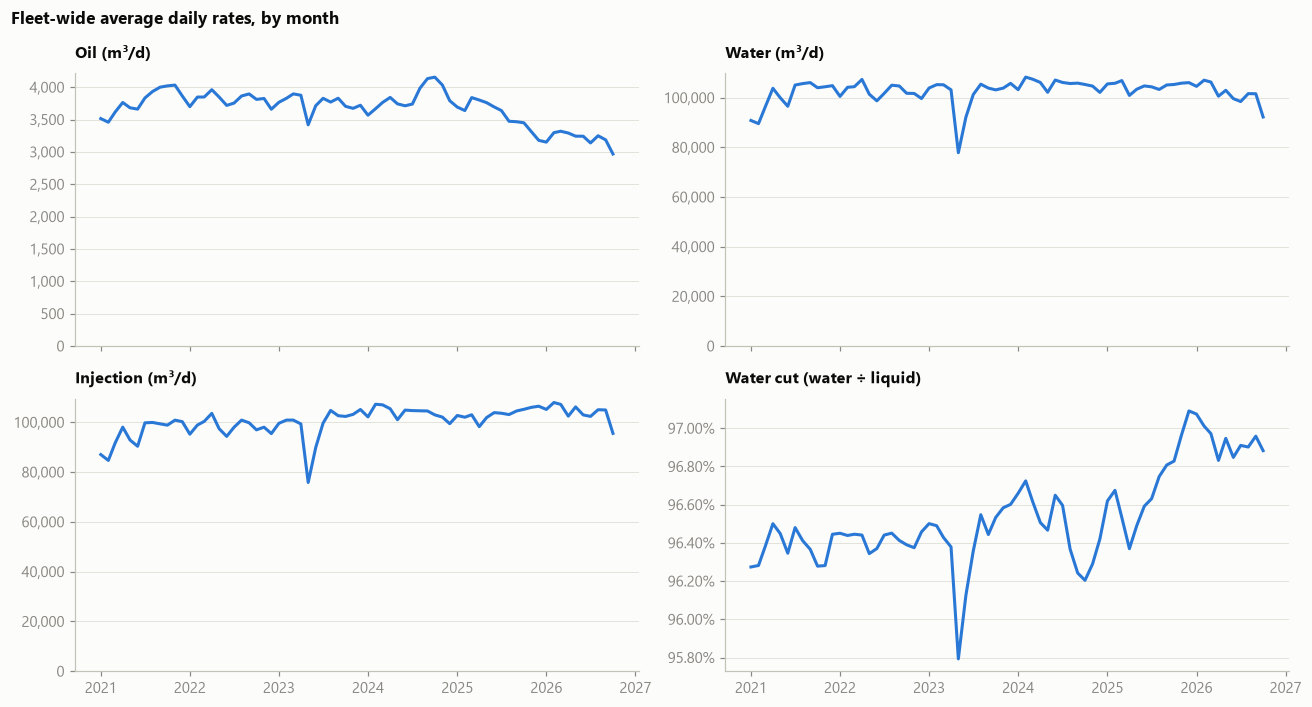

In [10]:
daily_tot = dp.groupby("production_date")[["oil_produced_m3", "water_produced_m3",
                                           "gas_produced_e3m3", "injection_volume_m3"]].sum()
monthly = daily_tot.resample("MS").mean()
monthly["water_cut"] = monthly.water_produced_m3 / (monthly.water_produced_m3 + monthly.oil_produced_m3)

panels = [("oil_produced_m3", "Oil (m³/d)"), ("water_produced_m3", "Water (m³/d)"),
          ("injection_volume_m3", "Injection (m³/d)"), ("water_cut", "Water cut (water ÷ liquid)")]
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for ax, (col, label) in zip(axes.flat, panels):
    ax.plot(monthly.index, monthly[col], color=BLUE)
    ax.set_title(label, fontsize=10.5)
    if col == "water_cut":
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    else:
        ax.yaxis.set_major_formatter(thousands); ax.set_ylim(bottom=0)
fig.suptitle("Fleet-wide average daily rates, by month", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

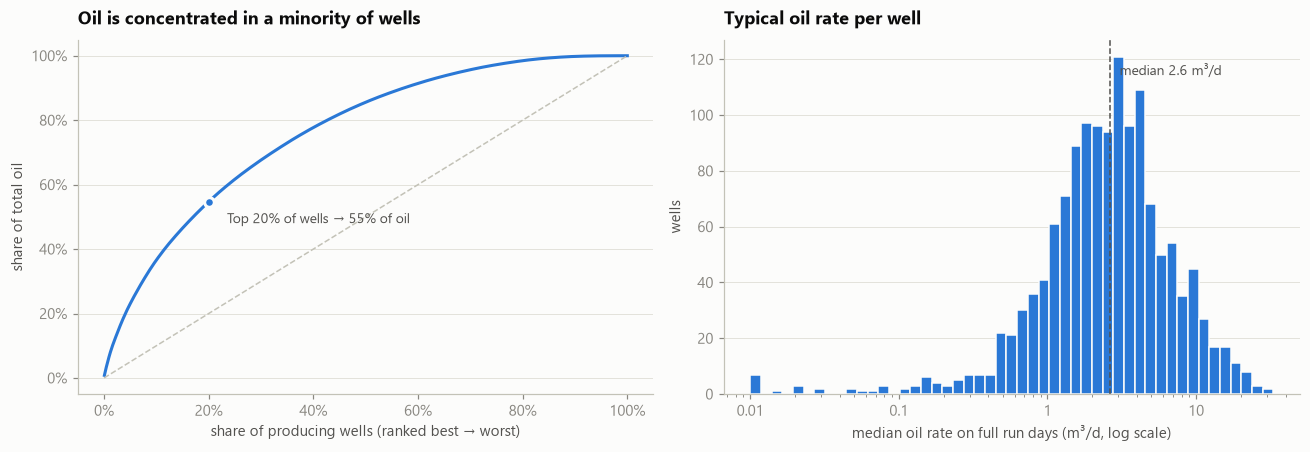

In [11]:
# Concentration: how much of the oil comes from the best wells?
prod = wells.loc[wells.oil_total > 0, "oil_total"].sort_values(ascending=False)
cum = prod.cumsum() / prod.sum()
share_wells = np.arange(1, len(prod) + 1) / len(prod)
top20 = cum.iloc[int(0.2 * len(prod)) - 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(share_wells, cum.values, color=BLUE)
ax1.plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--")
ax1.scatter([0.2], [top20], color=BLUE, s=40, zorder=3, edgecolor=SURFACE, linewidth=2)
ax1.annotate(f"Top 20% of wells → {top20:.0%} of oil", (0.2, top20), xytext=(12, -14),
             textcoords="offset points", fontsize=9, color=INK2)
ax1.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax1.set_xlabel("share of producing wells (ranked best → worst)"); ax1.set_ylabel("share of total oil")
ax1.set_title("Oil is concentrated in a minority of wells")

# Typical rate on days the well actually ran
running = dp[(dp.hours_on_prod > 20) & (dp.oil_produced_m3 > 0)]
rate = running.groupby("uwi", observed=True).oil_produced_m3.median()
ax2.hist(rate, bins=np.logspace(np.log10(max(rate.min(), 0.01)), np.log10(rate.max()), 50),
         color=BLUE, edgecolor=SURFACE, linewidth=1)
ax2.set_xscale("log"); ax2.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:g}"))
ax2.axvline(rate.median(), color=INK2, lw=1, ls="--")
ax2.annotate(f"median {rate.median():.1f} m³/d", (rate.median(), ax2.get_ylim()[1] * 0.9),
             xytext=(6, 0), textcoords="offset points", fontsize=9, color=INK2)
ax2.set_xlabel("median oil rate on full run days (m³/d, log scale)"); ax2.set_ylabel("wells")
ax2.set_title("Typical oil rate per well")
plt.tight_layout(); plt.show()

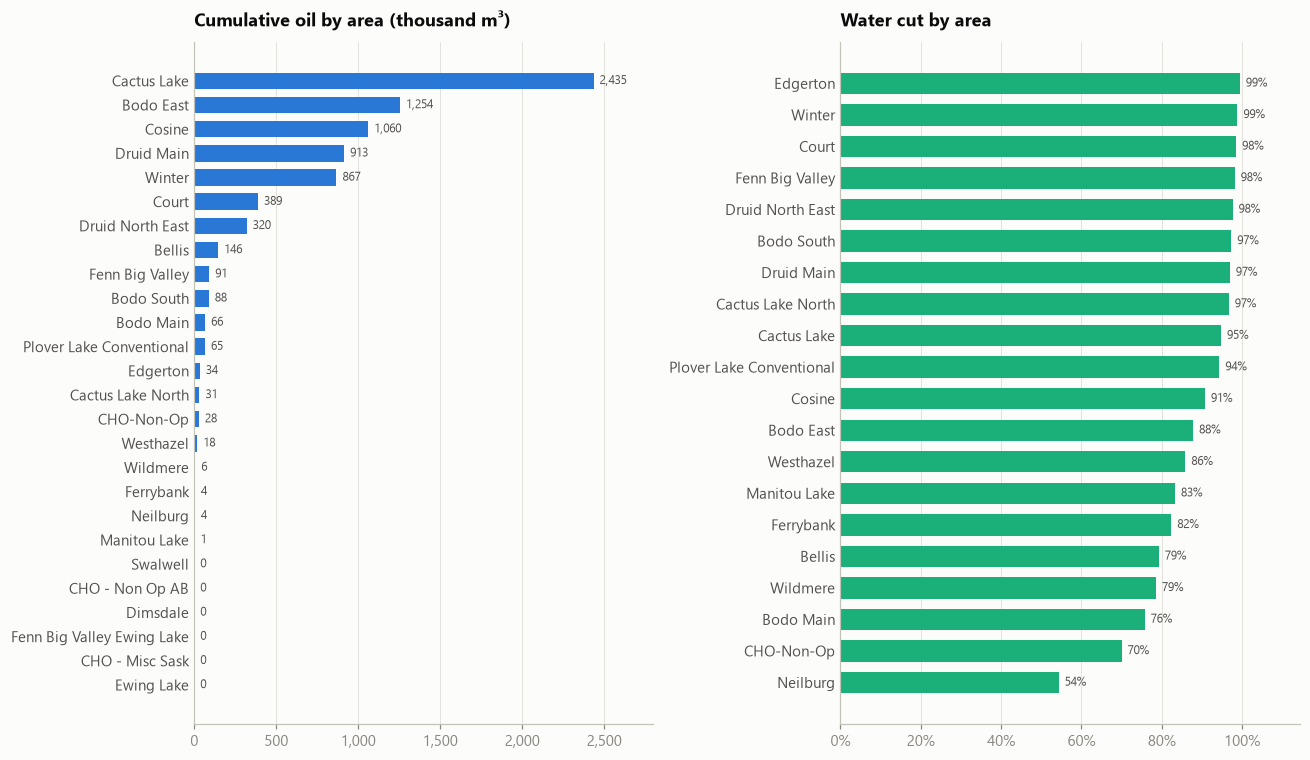

In [12]:
area_oil = dp.groupby("field_operating_area", observed=True).oil_produced_m3.sum() / 1e3
area_wc = (dp.groupby("field_operating_area", observed=True)[["water_produced_m3", "oil_produced_m3"]].sum()
           .pipe(lambda d: d.water_produced_m3 / (d.water_produced_m3 + d.oil_produced_m3)))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 7))
hbar(ax1, area_oil, title="Cumulative oil by area (thousand m³)")
hbar(ax2, area_wc[area_oil.reindex(area_wc.index) > 1], fmt="{:.0%}", color=AQUA,
     title="Water cut by area")
ax2.xaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.tight_layout(); plt.show()

## 5 · Downtime and lost oil

`lost_oil_m3` is the operator's estimate of the oil a well would have made while it was down. This is the most direct measure of what downtime costs.

Total oil produced:       7,818,409 m³  (≈ 49.2 million bbl)
Total estimated lost:       603,853 m³  (≈ 3.8 million bbl)  = 7.2% of potential


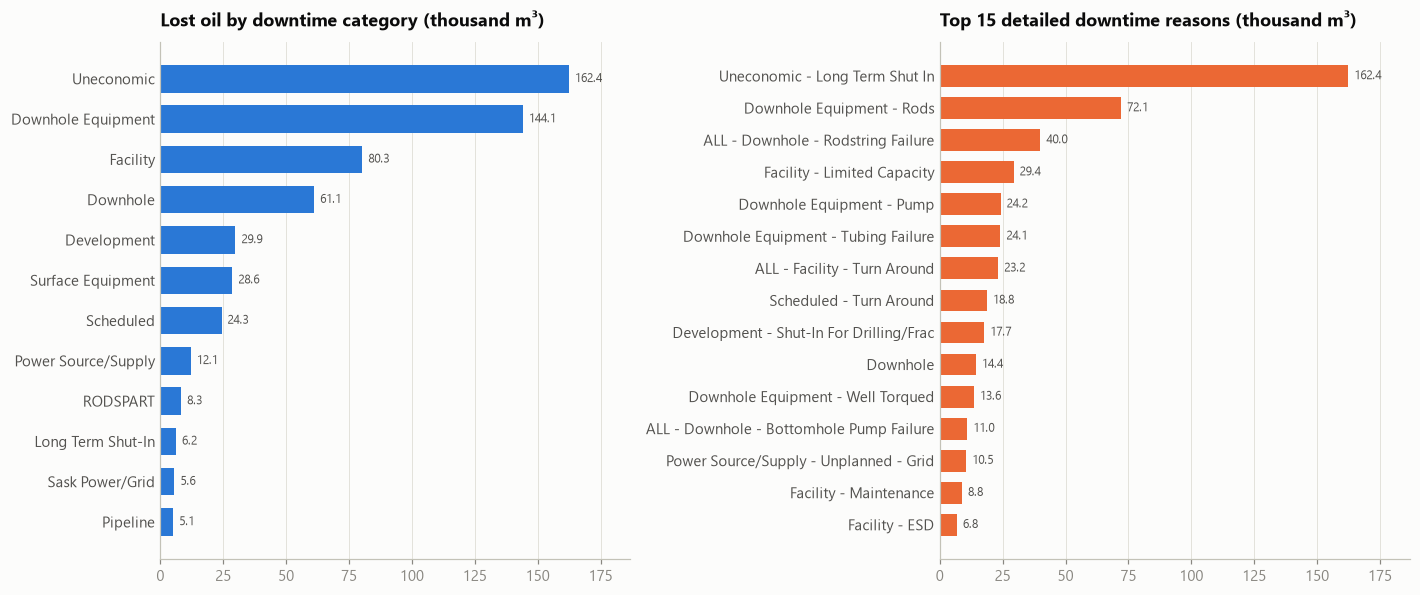

In [13]:
total_lost, total_oil = dp.lost_oil_m3.sum(), dp.oil_produced_m3.sum()
print(f"Total oil produced:  {total_oil:>14,.0f} m³  (≈ {total_oil*6.29/1e6:,.1f} million bbl)")
print(f"Total estimated lost:{total_lost:>14,.0f} m³  (≈ {total_lost*6.29/1e6:,.1f} million bbl)  "
      f"= {total_lost/(total_oil+total_lost):.1%} of potential")

down = dp[dp.lost_oil_m3 > 0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
hbar(ax1, down.groupby("downtime_code_2", observed=True).lost_oil_m3.sum().nlargest(12) / 1e3,
     fmt="{:,.1f}", title="Lost oil by downtime category (thousand m³)")
hbar(ax2, down.groupby("downtime_code_1", observed=True).lost_oil_m3.sum().nlargest(15) / 1e3,
     fmt="{:,.1f}", color=ORANGE, title="Top 15 detailed downtime reasons (thousand m³)")
plt.tight_layout(); plt.show()

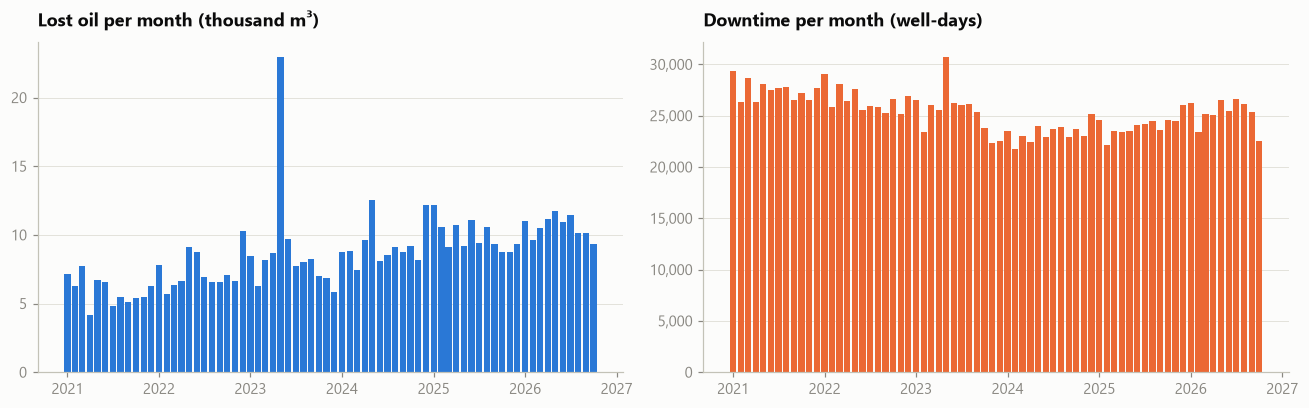

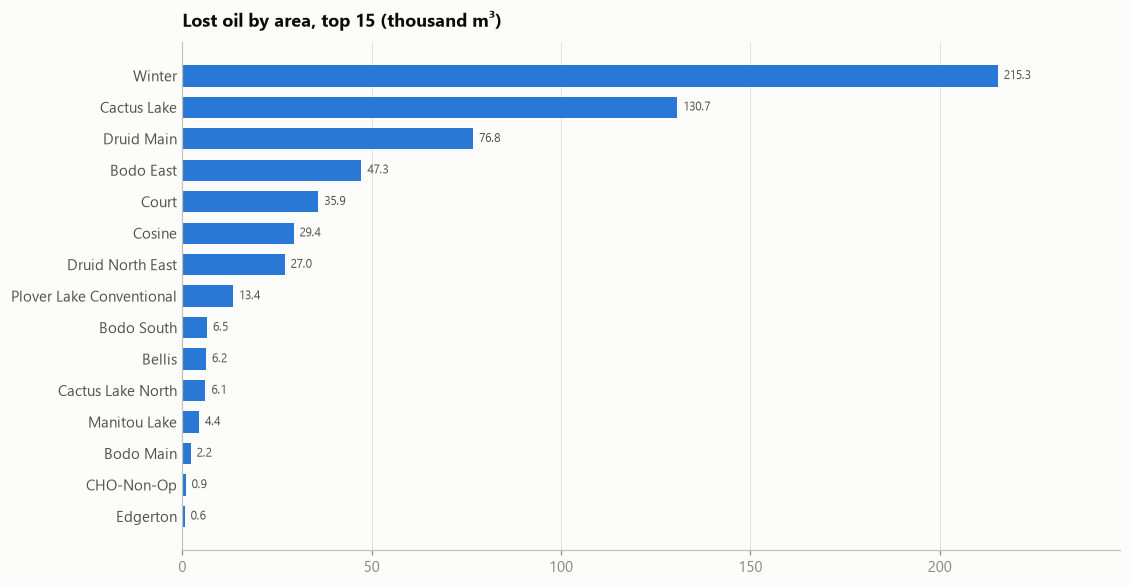

In [14]:
lost_m = dp.groupby("production_date").lost_oil_m3.sum().resample("MS").sum() / 1e3
down_h = dp.groupby("production_date").hours_down.sum().resample("MS").sum() / 24  # well-days down

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.bar(lost_m.index, lost_m.values, width=25, color=BLUE)
ax1.set_title("Lost oil per month (thousand m³)"); ax1.yaxis.set_major_formatter(thousands)
ax2.bar(down_h.index, down_h.values, width=25, color=ORANGE)
ax2.set_title("Downtime per month (well-days)"); ax2.yaxis.set_major_formatter(thousands)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 6))
hbar(ax, down.groupby("field_operating_area", observed=True).lost_oil_m3.sum().nlargest(15) / 1e3,
     fmt="{:,.1f}", title="Lost oil by area, top 15 (thousand m³)")
plt.show()

## 6 · Pump sensors (PCP)

Daily summaries of historian tags. Shown clipped to the 1st–99th percentile, with placeholder values (≥ 99,999) removed. Rising torque or current, or falling efficiency, are classic signs of wear.

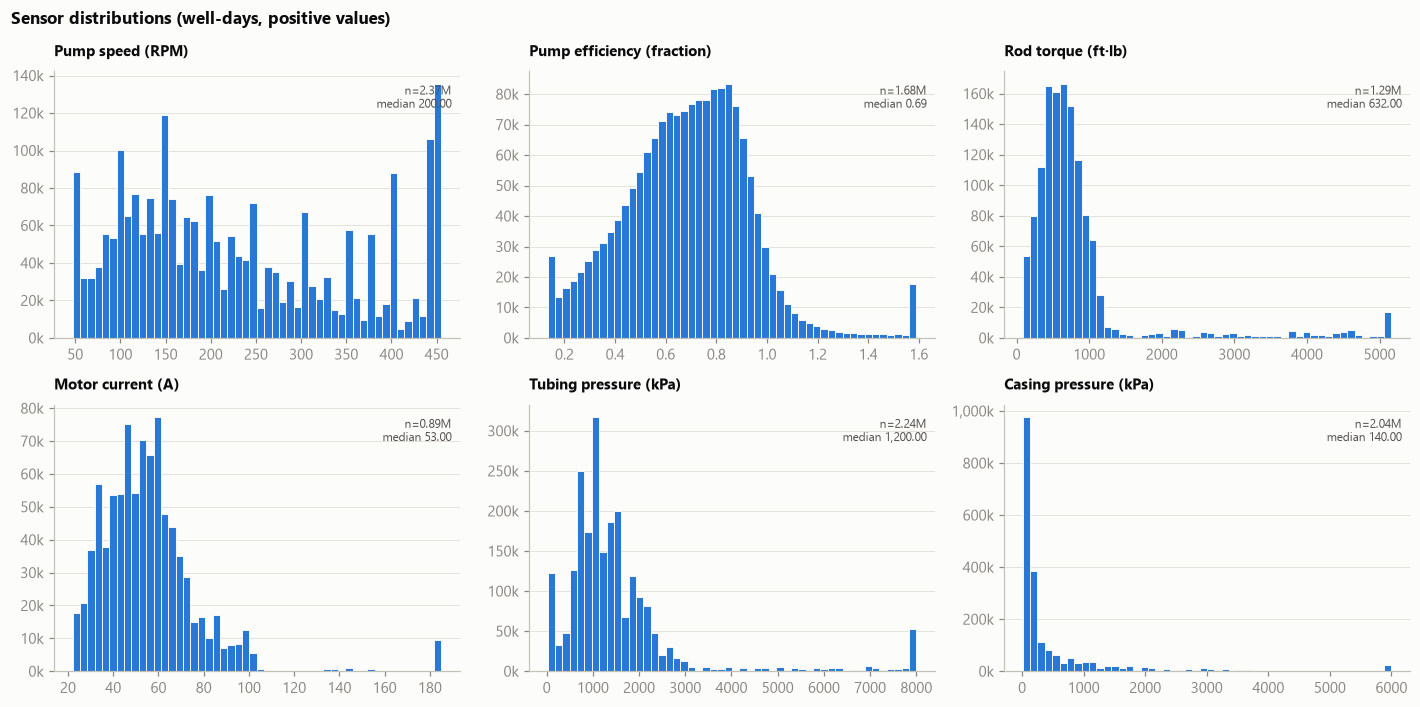

In [15]:
sensor_cols = [("pcp_pump_rpm", "Pump speed (RPM)"), ("pump_efficiency_pct", "Pump efficiency (fraction)"),
               ("pcp_pump_rod_torque_ftlb", "Rod torque (ft·lb)"), ("pcp_pump_electric_current_a", "Motor current (A)"),
               ("tubing_pressure_kpa", "Tubing pressure (kPa)"), ("casing_pressure_kpa", "Casing pressure (kPa)")]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (col, label) in zip(axes.flat, sensor_cols):
    s = dp[col].dropna()
    s = s[(s < 99_999) & (s > 0)]
    lo, hi = s.quantile([0.01, 0.99])
    ax.hist(s.clip(lo, hi), bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
    ax.set_title(label, fontsize=10)
    ax.text(0.98, 0.95, f"n={len(s)/1e6:.2f}M\nmedian {s.median():,.2f}", transform=ax.transAxes,
            ha="right", va="top", fontsize=8, color=INK2)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}k"))
fig.suptitle("Sensor distributions (well-days, positive values)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

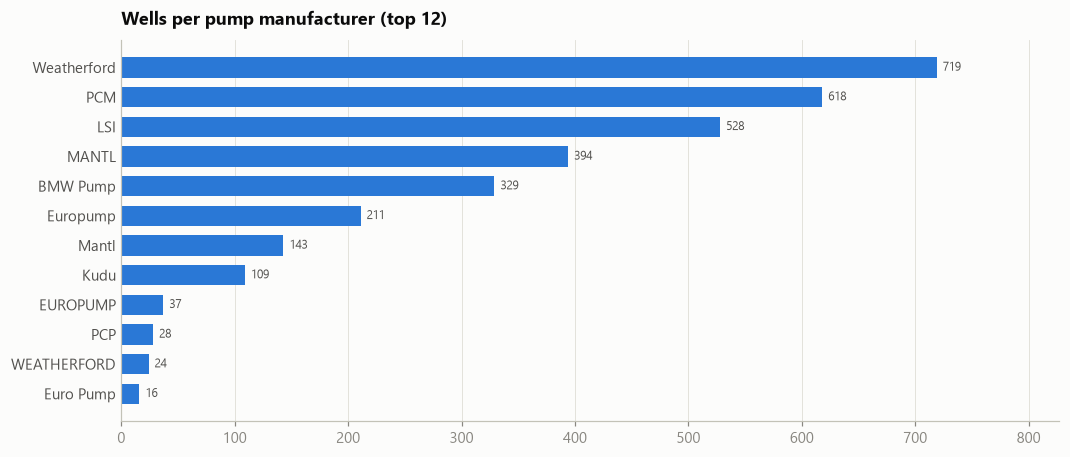

In [16]:
pump_wells = dp.dropna(subset=["pcp_pump_make"]).groupby("pcp_pump_make", observed=True).uwi.nunique()
fig, ax = plt.subplots(figsize=(11, 4.5))
hbar(ax, pump_wells.nlargest(12), title="Wells per pump manufacturer (top 12)")
plt.show()

## 7 · Failures

2.9k failures on about 825 wells. Rods dominate. Raw counts favour big areas, so the area view is **normalised per 100 producing well-years**.

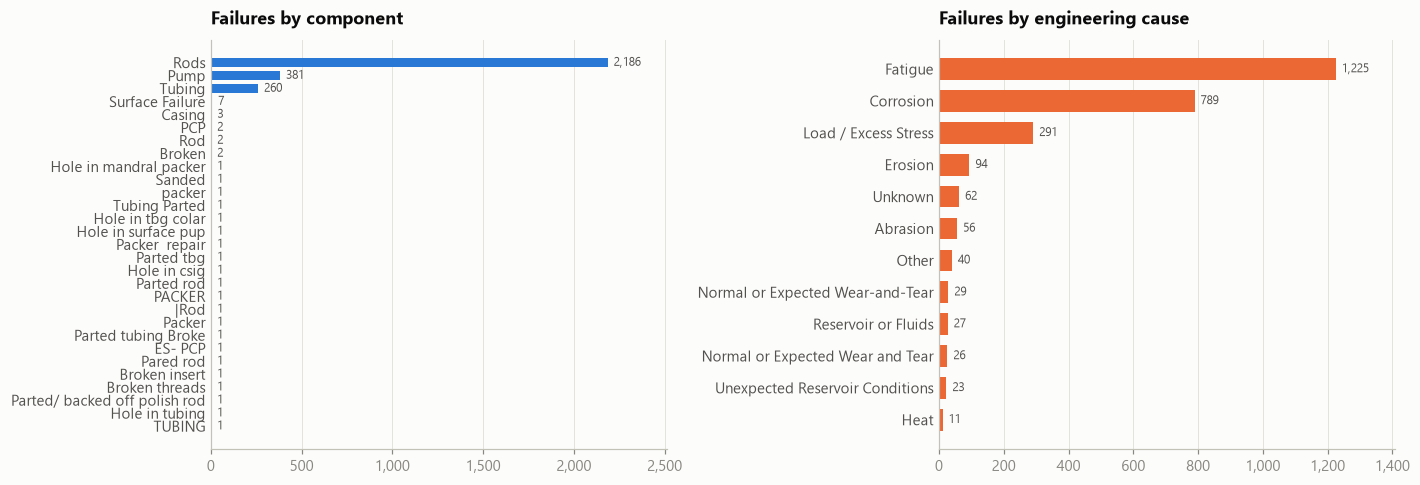

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
hbar(ax1, fails.failure_type.astype(str).value_counts(), title="Failures by component")
hbar(ax2, fails.cause.astype(str).value_counts().head(12), color=ORANGE, title="Failures by engineering cause")
plt.tight_layout(); plt.show()

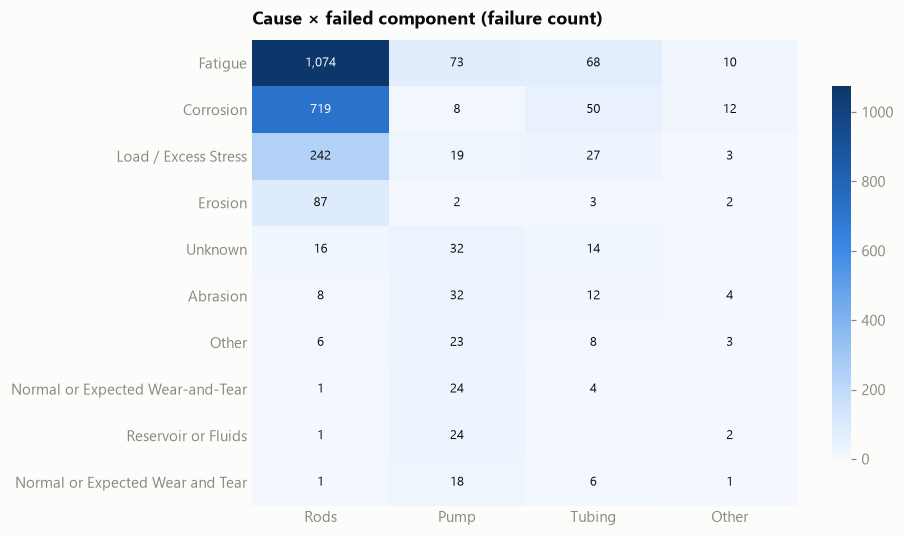

In [18]:
ftype = fails.failure_type.astype(str)
ftype = ftype.where(ftype.isin(["Rods", "Pump", "Tubing"]), "Other")
ct = pd.crosstab(fails.cause.astype(str), ftype)
ct = ct.loc[ct.sum(axis=1).nlargest(10).index, ["Rods", "Pump", "Tubing", "Other"]]
fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(ct.values, cmap=SEQ_BLUES, aspect="auto")
ax.set_xticks(range(ct.shape[1]), ct.columns); ax.set_yticks(range(ct.shape[0]), ct.index)
ax.grid(False); ax.tick_params(length=0)
for sp in ax.spines.values(): sp.set_visible(False)
vmax = ct.values.max()
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.values[i, j]
        if v: ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=8.5,
                      color="#ffffff" if v > vmax * 0.5 else INK)
ax.set_title("Cause × failed component (failure count)")
cb = plt.colorbar(im, ax=ax, shrink=0.8); cb.outline.set_visible(False)
plt.show()

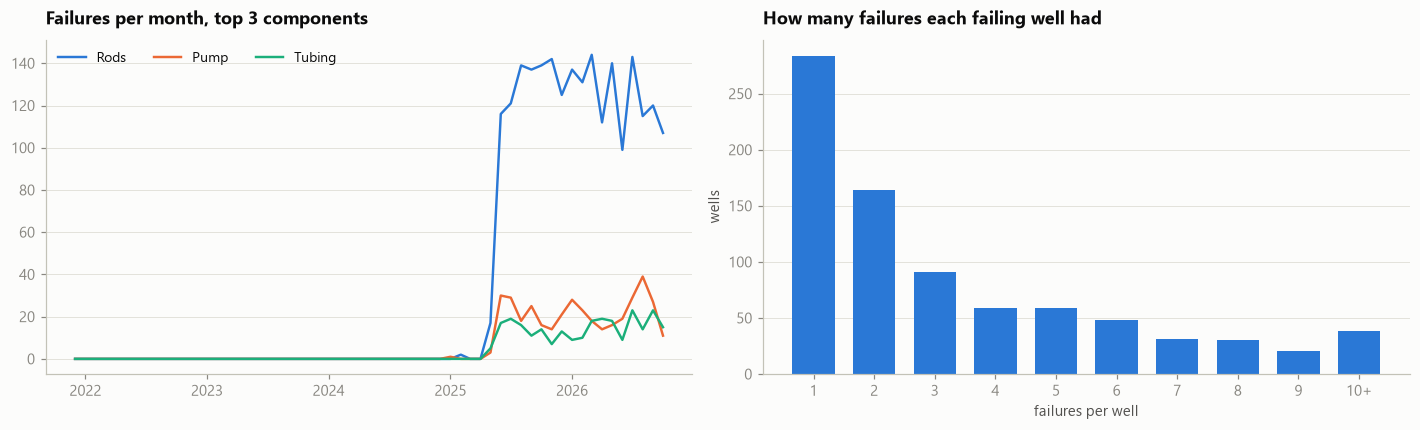

227 wells with 5+ failures account for 61% of all failures


In [19]:
f_month = fails.set_index("failure_start_date").resample("MS").size()
top_types = fails.failure_type.astype(str).value_counts().index[:3]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for t, color in zip(top_types, SERIES):
    y = fails[fails.failure_type.astype(str) == t].set_index("failure_start_date").resample("MS").size()
    y = y.reindex(f_month.index, fill_value=0)
    ax1.plot(y.index, y.values, color=color, label=t, lw=1.6)
ax1.set_title("Failures per month, top 3 components"); ax1.legend(loc="upper left", ncols=3)

per_well = fails.groupby("uwi", observed=True).size()
vc = per_well.clip(upper=10).value_counts().sort_index()
ax2.bar([str(i) if i < 10 else "10+" for i in vc.index], vc.values, color=BLUE, width=0.7)
ax2.set_title("How many failures each failing well had"); ax2.set_xlabel("failures per well"); ax2.set_ylabel("wells")
plt.tight_layout(); plt.show()
print(f"{(per_well >= 5).sum()} wells with 5+ failures account for "
      f"{per_well[per_well >= 5].sum() / len(fails):.0%} of all failures")

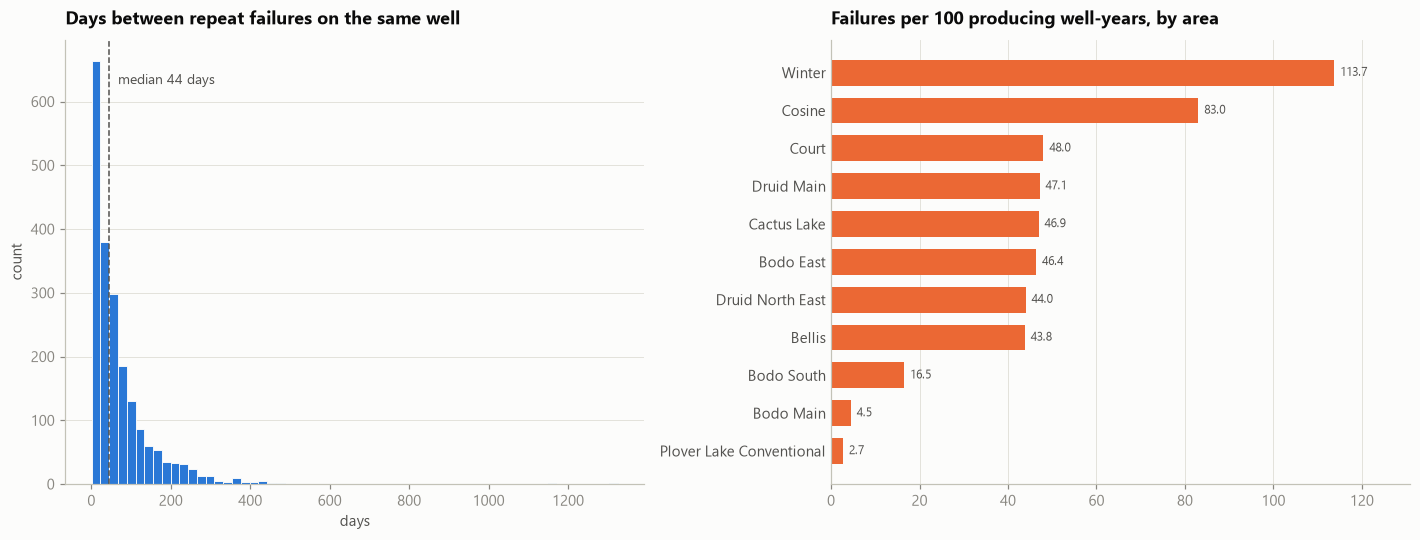

In [20]:
# Days between consecutive failures on the same well
f_sorted = fails.sort_values(["uwi", "failure_start_date"])
gap = f_sorted.groupby("uwi", observed=True).failure_start_date.diff().dt.days.dropna()
gap = gap[gap > 0]

# Failure rate per area, normalised by producing well-years over the same window
win = dp[(dp.production_date >= fails.failure_start_date.min()) & (dp.well_daily_status == "Producing")]
well_years = win.groupby("field_operating_area", observed=True).size() / 365.25
well_years.index = well_years.index.astype(str)
f_area = fails.field_operating_area.astype(str).value_counts()
rate = (f_area / well_years * 100).dropna()
rate = rate[well_years.reindex(rate.index) > 50]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.hist(gap, bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax1.axvline(gap.median(), color=INK2, ls="--", lw=1)
ax1.annotate(f"median {gap.median():.0f} days", (gap.median(), ax1.get_ylim()[1] * 0.9),
             xytext=(6, 0), textcoords="offset points", color=INK2, fontsize=9)
ax1.set_title("Days between repeat failures on the same well"); ax1.set_xlabel("days"); ax1.set_ylabel("count")
hbar(ax2, rate, fmt="{:.1f}", color=ORANGE, title="Failures per 100 producing well-years, by area")
plt.tight_layout(); plt.show()

## 8 · Jobs and cost

`field_est_total` is filled for nearly every job and is the practical cost column. AFE costs exist only for larger jobs (about 5%).

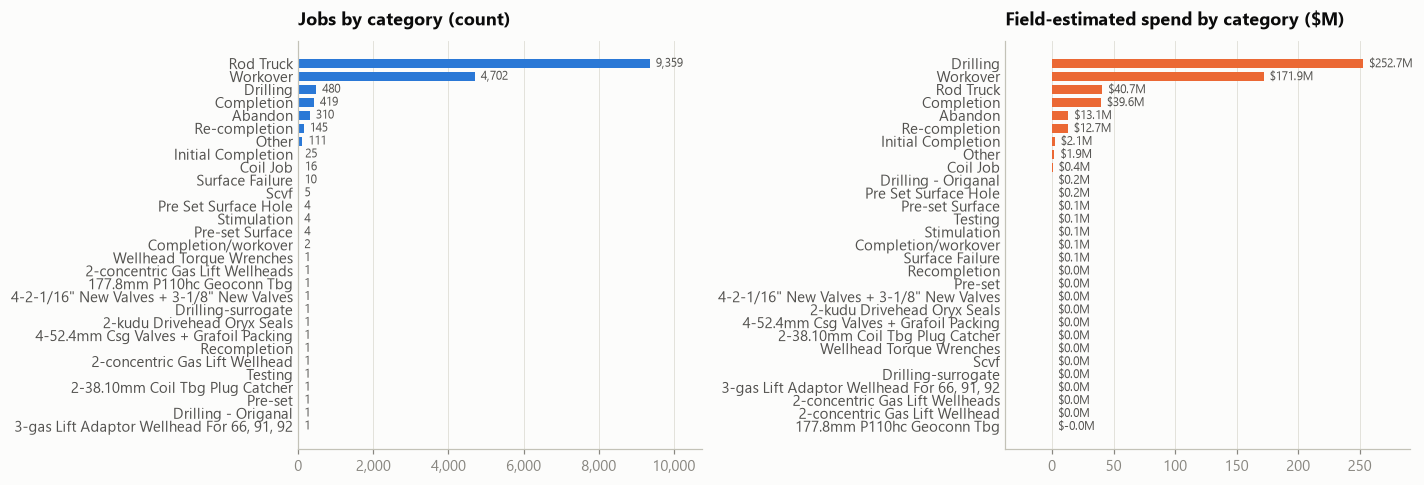

Total field-estimated spend: $536.1M over 15,610 jobs


In [21]:
cat_n = jobs.job_category.astype(str).value_counts()
cat_cost = jobs.groupby(jobs.job_category.astype(str)).field_est_total.sum() / 1e6

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
hbar(ax1, cat_n, title="Jobs by category (count)")
hbar(ax2, cat_cost, fmt="${:,.1f}M", color=ORANGE, title="Field-estimated spend by category ($M)")
plt.tight_layout(); plt.show()
print(f"Total field-estimated spend: ${jobs.field_est_total.sum()/1e6:,.1f}M over {len(jobs):,} jobs")

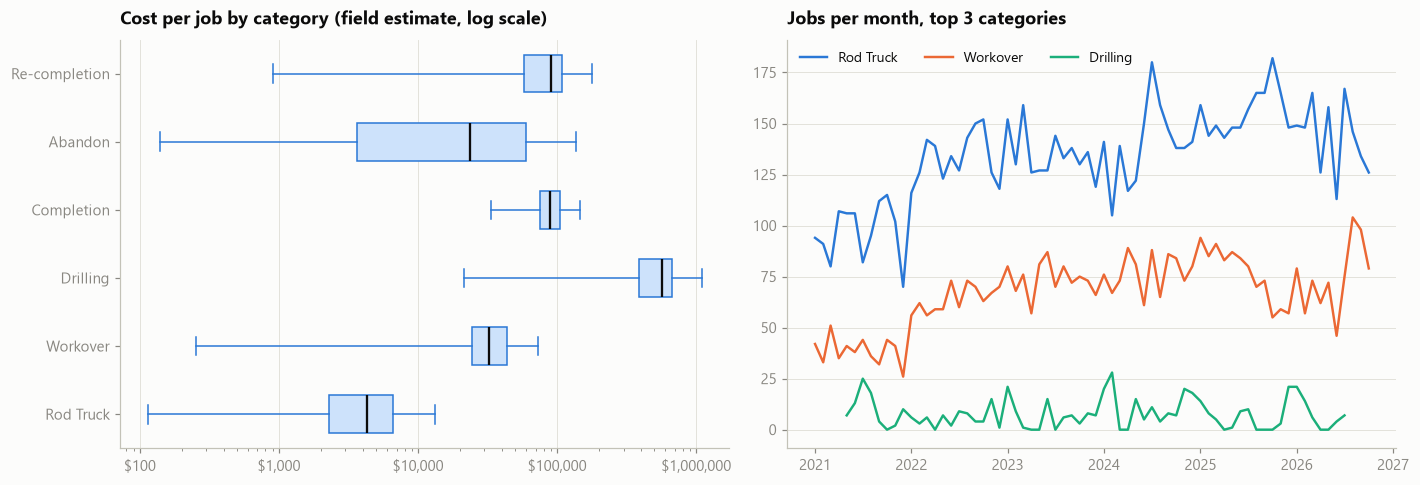

In [22]:
top_cats = cat_n.index[:6]
data = [jobs.loc[(jobs.job_category.astype(str) == c) & (jobs.field_est_total > 0), "field_est_total"] for c in top_cats]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
bp = ax1.boxplot(data, orientation="horizontal", showfliers=False, widths=0.55, patch_artist=True,
                 medianprops=dict(color=INK, lw=1.5),
                 boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE),
                 whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
ax1.set_yticks(range(1, len(top_cats) + 1), top_cats)
ax1.set_xscale("log"); ax1.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax1.grid(axis="y", visible=False); ax1.grid(axis="x", visible=True)
ax1.set_title("Cost per job by category (field estimate, log scale)")

for c, color in zip(cat_n.index[:3], SERIES):
    y = jobs[jobs.job_category.astype(str) == c].set_index("start_date").resample("MS").size()
    ax2.plot(y.index, y.values, color=color, label=c, lw=1.6)
ax2.set_title("Jobs per month, top 3 categories"); ax2.legend(loc="upper left", ncols=3)
plt.tight_layout(); plt.show()

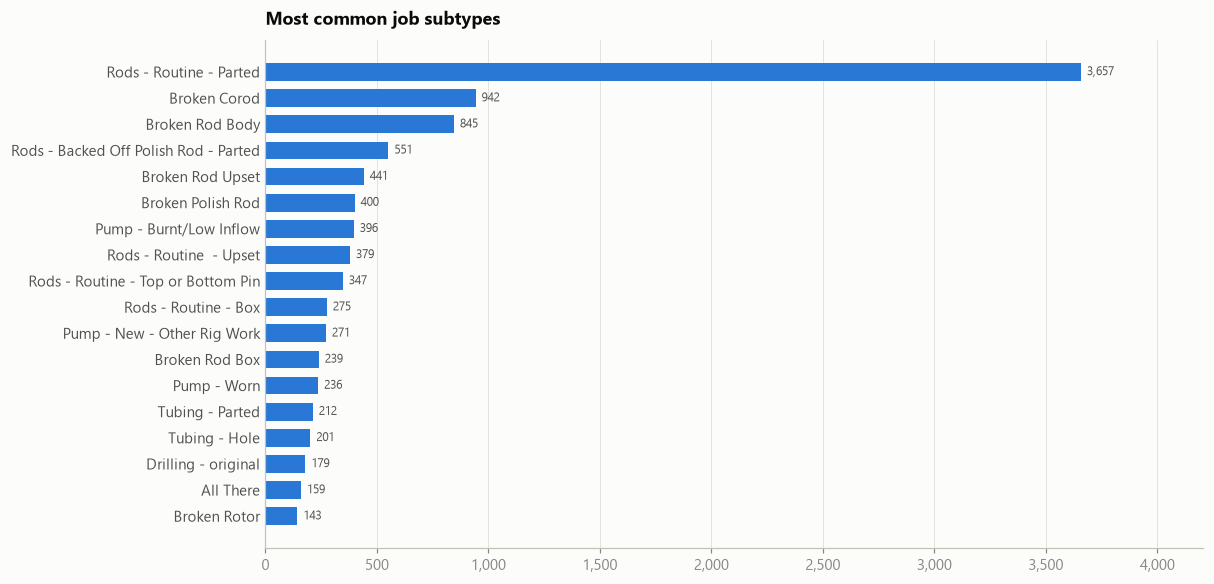

In [23]:
fig, ax = plt.subplots(figsize=(11, 6))
hbar(ax, jobs.job_subtype.astype(str).value_counts().drop("nan", errors="ignore").head(18),
     title="Most common job subtypes")
plt.show()

## 9 · Linking the files

This is where the interesting questions live. Two **event studies** line up many events on day 0 and take the median behaviour of each signal around it:

1. **Before a failure.** Do the pump signals drift in the weeks leading up to it? If they do, failures can be predicted (predictive maintenance).
2. **After a job.** How much oil does a job recover, and for how long? This measures maintenance effectiveness.

Each signal is divided by that event's own baseline median (days −90…−61 for failures, −60…−31 for jobs), so 1.0 means "normal for this well".

In [24]:
def event_panel(events, date_col, lo, hi, cols):
    """Long table: one row per (event, day offset) with the well's daily values attached."""
    ev = events[["uwi", date_col]].dropna().copy()
    ev["uwi"] = ev["uwi"].astype(str)
    ev = ev.rename(columns={date_col: "t0"}).reset_index(drop=True)
    ev["event_id"] = ev.index
    grid = ev.merge(pd.DataFrame({"offset": np.arange(lo, hi + 1)}), how="cross")
    grid["production_date"] = grid.t0 + pd.to_timedelta(grid.offset, unit="D")
    sub = dp.loc[dp.uwi.isin(ev.uwi.unique()), ["uwi", "production_date", *cols]].copy()
    sub["uwi"] = sub.uwi.astype(str)
    sub = sub.drop_duplicates(["uwi", "production_date"])
    return grid.merge(sub, on=["uwi", "production_date"], how="left")

def relative_profile(panel, cols, base_lo, base_hi, stat="mean"):
    """Each event's signal ÷ its own baseline median, then averaged across events per day offset.
    Ratios are clipped to [0, 3] so a handful of extreme wells can't dominate the mean."""
    base = panel[panel.offset.between(base_lo, base_hi)].groupby("event_id")[cols].median()
    base = base.where(base > 0)
    rel = panel[cols].div(base.reindex(panel.event_id).to_numpy()).clip(0, 3)
    rel["offset"] = panel.offset.to_numpy()
    g = rel.groupby("offset")
    return getattr(g, stat)(), g.count()

SIG = [("oil_produced_m3", "Oil rate"), ("pcp_pump_rod_torque_ftlb", "Rod torque"),
       ("pcp_pump_electric_current_a", "Motor current"), ("pump_efficiency_pct", "Pump efficiency"),
       ("pcp_pump_rpm", "Pump speed"), ("hours_on_prod", "Hours on production")]
cols = [c for c, _ in SIG]
f_panel = event_panel(fails, "failure_start_date", -90, 30, cols)
f_prof, f_n = relative_profile(f_panel, cols, -90, -61)

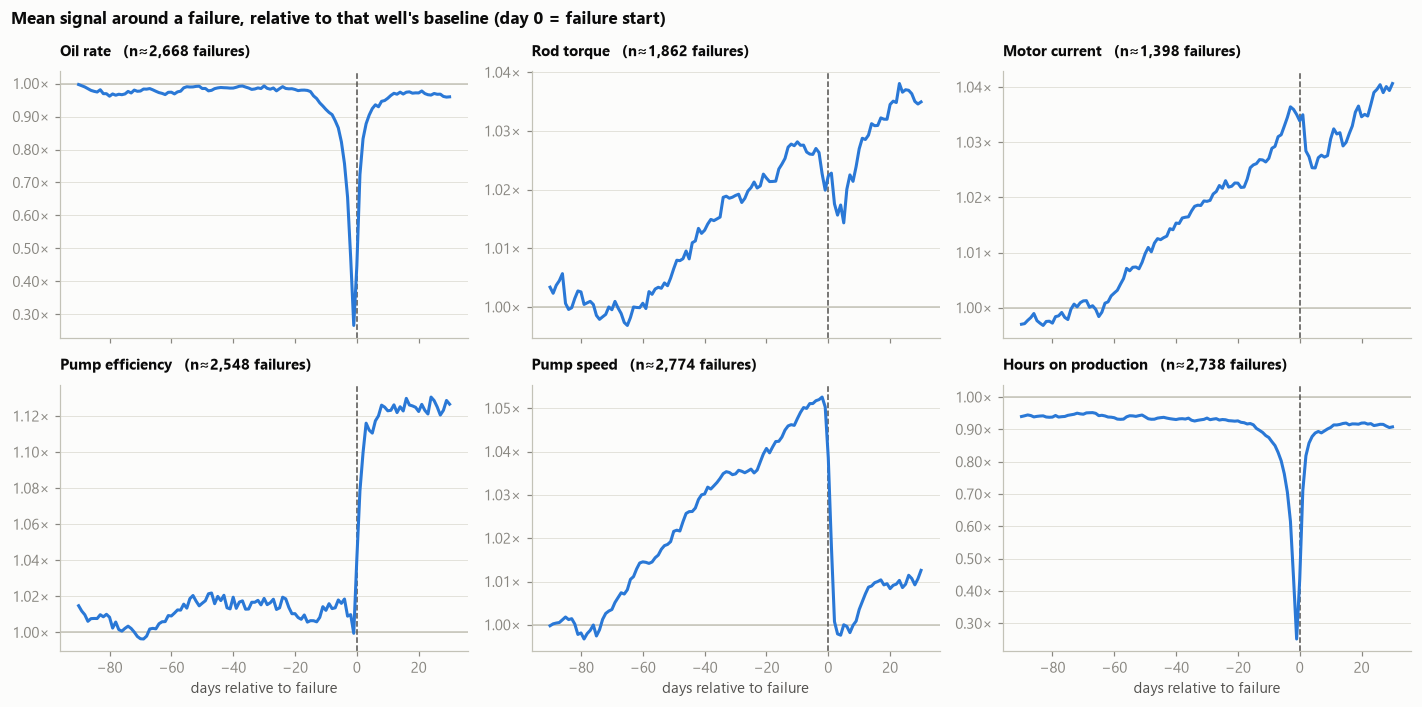

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for ax, (col, label) in zip(axes.flat, SIG):
    ax.axhline(1, color=AXIS, lw=1)
    ax.axvline(0, color=INK2, lw=1, ls="--")
    ax.plot(f_prof.index, f_prof[col], color=BLUE)
    ax.set_title(f"{label}   (n≈{int(f_n[col].loc[-30]):,} failures)", fontsize=10)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:.2f}×"))
for ax in axes[-1]: ax.set_xlabel("days relative to failure")
fig.suptitle("Mean signal around a failure, relative to that well's baseline (day 0 = failure start)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

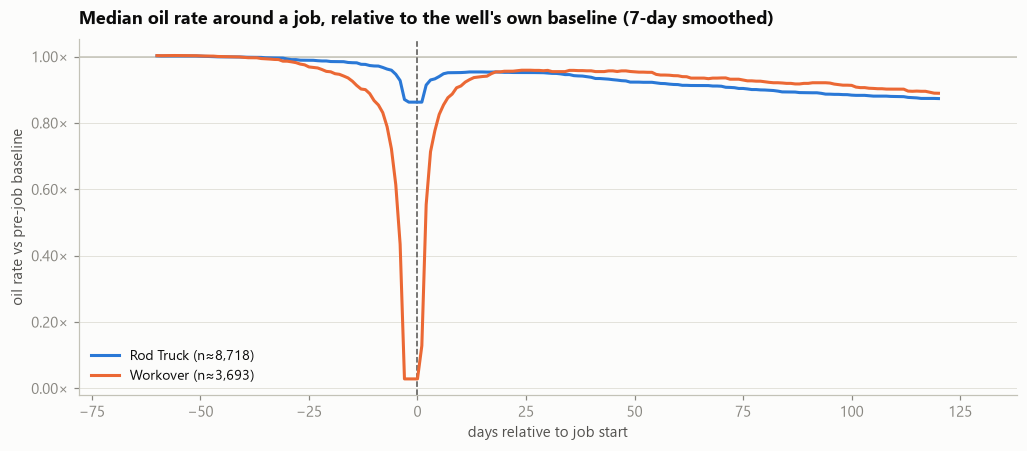

In [26]:
job_cats = jobs.job_category.astype(str).value_counts().index[:2]
j_sel = jobs[jobs.job_category.astype(str).isin(job_cats)]
j_panel = event_panel(j_sel, "start_date", -60, 120, ["oil_produced_m3"])
j_panel["cat"] = j_sel.job_category.astype(str).to_numpy()[j_panel.event_id]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.axhline(1, color=AXIS, lw=1); ax.axvline(0, color=INK2, lw=1, ls="--")
for c, color in zip(job_cats, SERIES):
    p = j_panel[j_panel.cat == c].reset_index(drop=True)
    prof, n = relative_profile(p, ["oil_produced_m3"], -60, -31, stat="median")
    y = prof.oil_produced_m3.rolling(7, center=True, min_periods=1).median()
    ax.plot(y.index, y.values, color=color, label=f"{c} (n≈{int(n.oil_produced_m3.loc[-45]):,})")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:.2f}×"))
ax.set_xlabel("days relative to job start"); ax.set_ylabel("oil rate vs pre-job baseline")
ax.set_title("Median oil rate around a job, relative to the well's own baseline (7-day smoothed)")
ax.legend(loc="lower left"); ax.margins(x=0.1)
plt.show()

In [27]:
# How well do failures and jobs line up? (a failure should usually trigger a job)
fj = fails[["uwi", "failure_start_date"]].assign(uwi=lambda d: d.uwi.astype(str)).reset_index(names="fid").merge(
    jobs[["uwi", "start_date", "job_category"]].assign(uwi=lambda d: d.uwi.astype(str)), on="uwi", how="left")
fj["lag"] = (fj.start_date - fj.failure_start_date).dt.days
matched = fj[fj.lag.between(-3, 30)].sort_values("lag").drop_duplicates("fid")
print(f"{len(matched)/len(fails):.0%} of failures have a job on the same well within -3…+30 days")
print("Category of that job:\n" + matched.job_category.astype(str).value_counts().head(5).to_string())
print(f"Median lag failure → job: {matched.lag.median():.0f} days")

99% of failures have a job on the same well within -3…+30 days
Category of that job:
job_category
Rod Truck        2219
Workover          604
Re-completion       6
Other               4
Completion          1
Median lag failure → job: 0 days


## 10 · Takeaways and possible research questions

**What the data says so far** (numbers from the full dataset):

- **Scale.** About 7.8M m³ of oil (≈ 49M bbl) produced, and about 0.6M m³ **lost to downtime**, which is ~7% of potential. Water cut is ~96–97% and creeping up, while fleet oil has trended down since late 2024.
- **Concentration.** The top 20% of producing wells make ~55% of the oil. The median well makes only ~2.6 m³/d, so protecting the best wells matters most.
- **Where lost oil goes.** "Uneconomic – long-term shut-in" is the biggest bucket, but it is a business decision. Among *fixable* losses, **rod failures** dominate (downhole equipment – rods, rod-string failure), followed by facility capacity and pump/tubing failures.
- **Failures are concentrated.** About 76% are rods, and fatigue and corrosion are the main causes. Just 227 wells (5+ failures each) account for ~61% of all failures. The median gap between repeat failures on a well is ~44 days. **Winter** and **Cosine** fail at 2–4× the rate of other areas per producing well-year.
- **Early-warning signal exists.** In the ~60 days before a failure, the average well's **pump speed climbs ~5%, motor current ~3.5% and rod torque ~3%** above its own baseline, and oil and run-hours sag in the final 2 weeks. That suggests operators speeding up struggling pumps, which adds rod wear, so it is worth testing as a cause. Caveat: torque, current and RPM are infrequent manual readings carried forward (§2), so the signal is coarse and an ML model needs per-well, trend-based features.
- **Jobs ≈ failures.** 99% of failures have a rod-truck or workover job on the same well within a month (usually the same day). Total field-estimated spend is about $536M. Rod-truck jobs are cheap (median ~$4k) but frequent, and workovers cost about $30k each.
- **After a job,** oil rate only recovers to ~95% of the pre-job baseline and keeps declining.

**Research questions this suggests:**

1. *Predictive maintenance.* Can pump-efficiency and production trends flag a rod/pump failure 2–4 weeks ahead? What would that save in lost oil and emergency jobs?
2. *Chronic-failure wells.* What distinguishes the 227 repeat-failure wells (area, pump make/model, RPM, water cut, corrosion)? Is a redesign (e.g. different rods, lower RPM, corrosion inhibitor) worth it versus repeated rod-truck jobs?
3. *Intervention ROI.* Which job types and subtypes actually restore production, and which wells are no longer worth servicing given cost versus recovered oil?
4. *Area benchmarking.* Why do Winter and Cosine fail so much more often than other areas, and what would bringing them to the fleet average be worth?